# Config B — Thử nhóm nhãn thời tiết

## Mục tiêu

Kiểm tra xem thêm 11 cột nhãn thời tiết vào Config A có giảm MAE hay không. Dùng B đầy đủ để xem bốn biến thời tiết dạng số đóng góp thêm bao nhiêu khi mô hình đã có nhãn thời tiết.

- **A** có 12 đặc trưng thời gian và ngày lễ.
- **A + nhãn thời tiết** có 23 đặc trưng, gồm A và 11 cột cờ như `weather_clouds`, `weather_rain` và `weather_fog`.
- **B đầy đủ** có 27 đặc trưng, gồm 23 cột của phương án trên và `temp_c`, `rain_1h`, `snow_1h`, `clouds_all`.

Cả ba dùng cùng dữ liệu CSV gốc, mốc chia và bộ tham số Random Forest của [thí nghiệm thời tiết dạng số](../17-11-2026_ConfigB_WeatherNumeric_Phuc/configB_WeatherNumeric_Phuc.ipynb). Chọn theo MAE trung bình qua 3 fold theo thời gian. Xem thêm RMSE và MAE giờ cao điểm theo cờ `is_rush_hour`.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## Params

In [8]:
EXPERIMENT_NAME = "17-11-2026_ConfigB_WeatherLabels_Phuc"
MODEL_NAME = "Random Forest"
TARGET = "traffic_volume"
CV_SPLITS = 3
PRIMARY_METRIC = "MAE"
RUN_VALIDATION = True

DATA_PARAMS = {"mask_stuck_temp": False, "complete_holidays": False}

MODEL_PARAMS = {
    "n_estimators": 400,
    "max_depth": 12,
    "min_samples_leaf": 5,
    "max_features": 1.0,
    "random_state": 42,
    "n_jobs": -1,
}

## Import và tìm thư mục dự án

In [9]:
import json
import sys
import warnings
from pathlib import Path
from datetime import datetime, timezone, timedelta
from time import perf_counter

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit


def find_project_root():
    current = Path.cwd().resolve()

    for folder in (current, *current.parents):
        for candidate in (
            folder,
            folder / "metro_interstate_traffic_volume",
        ):
            if (
                (candidate / "src" / "models.py").is_file()
                and (candidate / "src" / "features.py").is_file()
            ):
                return candidate

    raise FileNotFoundError(
        "Không tìm thấy dự án. Hãy kiểm tra thư mục làm việc của kernel."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import features
from src.data import fill_missing_weather
from src.evaluation import clip_prediction, regression_metrics

DATA_PATH = PROJECT_ROOT / "data" / "Metro_Interstate_Traffic_Volume.csv"

RUN_ID = datetime.now(
    timezone(timedelta(hours=7))
).strftime("%Y%m%d_%H%M%S_%f")

OUTPUT_DIR = (
    PROJECT_ROOT
    / "experiments"
    / EXPERIMENT_NAME
    / "outputs"
    / RUN_ID
)

print("Project:", PROJECT_ROOT)
print("Data:", DATA_PATH)
print("Output:", OUTPUT_DIR)

assert DATA_PATH.is_file(), f"Không tìm thấy dữ liệu: {DATA_PATH}"
REFERENCE_DIR = PROJECT_ROOT / "experiments" / "13-11-2026_ConfigB_4Model_Phuc"

# Nạp lại pipeline Random Forest đã dùng ở các thí nghiệm trước của Phúc.
import importlib.util
spec = importlib.util.spec_from_file_location(
    "config_b_grid_cv", REFERENCE_DIR / "config_b_grid_cv.py"
)
grid_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(grid_module)
make_config_b_pipeline = grid_module.make_config_b_pipeline

Project: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume
Data: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\data\Metro_Interstate_Traffic_Volume.csv
Output: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\17-11-2026_ConfigB_WeatherLabels_Phuc\outputs\20261117_203112_824733


## Đọc dữ liệu và khai báo các nhóm đặc trưng

In [10]:
CONFIG_FEATURES = {
    "A": list(features.CONFIG_A),
    "A_labels": [*features.CONFIG_A, *features.WEATHER_GROUP_FEATURES],
    "B": list(features.CONFIG_B),
}

assert [len(columns) for columns in CONFIG_FEATURES.values()] == [12, 23, 27]
assert set(CONFIG_FEATURES["A_labels"]) < set(CONFIG_FEATURES["B"])
assert set(CONFIG_FEATURES["A_labels"]) - set(CONFIG_FEATURES["A"]) == set(
    features.WEATHER_GROUP_FEATURES
)
assert set(CONFIG_FEATURES["B"]) - set(CONFIG_FEATURES["A_labels"]) == set(
    features.WEATHER_NUMERIC_FEATURES
)
assert set(CONFIG_FEATURES["B"]).isdisjoint([TARGET, *features.HISTORY_FEATURES])

from src.experiment_data import load_experiment_splits
splits = load_experiment_splits(path=DATA_PATH, **DATA_PARAMS, stage="raw")
raw_train = splits["train"]
raw_validation = splits["validation"]

for frame in (raw_train, raw_validation):
    assert not frame.empty
    assert frame["date_time"].is_monotonic_increasing
    assert not frame["date_time"].duplicated().any()

assert raw_train["date_time"].max() < raw_validation["date_time"].min()

display(pd.DataFrame([
    {"config": name, "n_features": len(columns), "features": ", ".join(columns)}
    for name, columns in CONFIG_FEATURES.items()
]))
display(pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "start": frame["date_time"].min(),
        "end": frame["date_time"].max(),
    }
    for name, frame in (("train", raw_train), ("validation", raw_validation))
]))

,config,n_features,features
0,A,12,"hour, day_of_week, month, is_weekend, is_rush_..."
1,A_labels,23,"hour, day_of_week, month, is_weekend, is_rush_..."
2,B,27,"hour, day_of_week, month, is_weekend, is_rush_..."


,split,rows,start,end
0,train,28402,2012-10-02 09:00:00,2017-05-10 04:00:00
1,validation,6086,2017-05-10 05:00:00,2018-01-19 14:00:00


## Chuẩn bị fold và hàm tính điểm

Tính thống kê điền thiếu thời tiết từ phần train của mỗi fold. Chuẩn bị chung một bộ dữ liệu cho ba phương án, rồi chọn cột trước khi fit. Dùng thời tiết quan sát cùng giờ với lưu lượng cần dự đoán.

In [11]:
def prepare_pair(fit_rows, score_rows):
    parts = fill_missing_weather({
        "train": fit_rows.copy(),
        "validation": score_rows.copy(),
    })
    train = features.add_weather_features(features.add_time_features(parts["train"]))
    score = features.add_weather_features(features.add_time_features(parts["validation"]))
    return train, score


def fit_and_score(train, score, feature_columns):
    pipeline = make_config_b_pipeline(MODEL_NAME, MODEL_PARAMS)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        start = perf_counter()
        pipeline.fit(train[feature_columns], train[TARGET])
        fit_seconds = perf_counter() - start

        start = perf_counter()
        raw_prediction = pipeline.predict(score[feature_columns])
        predict_seconds = perf_counter() - start

    assert np.isfinite(raw_prediction).all()
    prediction = clip_prediction(raw_prediction)
    metrics = regression_metrics(score[TARGET], prediction)
    rush = score["is_rush_hour"].eq(1).to_numpy()
    rush_mae = float(np.mean(np.abs(score[TARGET].to_numpy()[rush] - prediction[rush]))) if rush.any() else np.nan

    row = {
        "model": MODEL_NAME,
        "n_features": len(feature_columns),
        "n_train": len(train),
        "n_score": len(score),
        "n_rush_hours": int(rush.sum()),
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        **metrics,
        "MAE_rush": rush_mae,
        "warnings": " | ".join(dict.fromkeys(str(w.message) for w in caught)),
    }
    return row, raw_prediction, prediction

## So sánh theo 3 fold thời gian

Ba phương án dùng chung các fold train, tổng cộng 9 lần fit. Đọc bảng tổng hợp theo MAE, sau đó xem bảng từng fold để kiểm tra chênh lệch. Cột `delta_MAE_vs_B` âm nghĩa là MAE thấp hơn B đầy đủ.

In [12]:
fold_rows = []
splitter = TimeSeriesSplit(n_splits=CV_SPLITS)
for fold, (fit_idx, score_idx) in enumerate(splitter.split(raw_train), start=1):
    train, score = prepare_pair(raw_train.iloc[fit_idx], raw_train.iloc[score_idx])
    for config, columns in CONFIG_FEATURES.items():
        print(f"Fold {fold}/{CV_SPLITS} · {config}", flush=True)
        row, _, _ = fit_and_score(train, score, columns)
        fold_rows.append({
            "config": config,
            "fold": fold,
            "fit_end": train["date_time"].max(),
            "score_start": score["date_time"].min(),
            "score_end": score["date_time"].max(),
            **row,
        })

cv_scores = pd.DataFrame(fold_rows)
cv_summary = (
    cv_scores.groupby("config", sort=False)
    .agg(
        n_features=("n_features", "first"),
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", lambda scores: scores.std(ddof=0)),
        mean_RMSE=("RMSE", "mean"),
        mean_R2=("R2", "mean"),
        mean_MAE_rush=("MAE_rush", "mean"),
    )
    .sort_values(f"mean_{PRIMARY_METRIC}", kind="stable")
)
cv_summary["delta_MAE_vs_B"] = cv_summary["mean_MAE"] - cv_summary.loc["B", "mean_MAE"]
display(cv_summary.round(4))
display(cv_scores.pivot(index="config", columns="fold", values="MAE").round(4))

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cv_scores.to_csv(OUTPUT_DIR / "cv_fold_scores.csv", index=False)
cv_summary.to_csv(OUTPUT_DIR / "cv_summary.csv")
(OUTPUT_DIR / "run_config.json").write_text(
    json.dumps({
        "dataset": str(DATA_PATH.relative_to(PROJECT_ROOT)),
        "data_params": DATA_PARAMS,
        "cv_splits": CV_SPLITS,
        "primary_metric": PRIMARY_METRIC,
        "model": MODEL_NAME,
        "model_params": MODEL_PARAMS,
        "features": CONFIG_FEATURES,
    }, indent=2),
    encoding="utf-8",
)

Fold 1/3 · A
Fold 1/3 · A_labels
Fold 1/3 · B
Fold 2/3 · A
Fold 2/3 · A_labels
Fold 2/3 · B
Fold 3/3 · A
Fold 3/3 · A_labels
Fold 3/3 · B


,n_features,mean_MAE,std_MAE,mean_RMSE,mean_R2,mean_MAE_rush,delta_MAE_vs_B
config,,,,,,,
A,12,280.6167,24.0021,461.3954,0.9452,411.4923,-0.6673
B,27,281.2840,21.5292,467.1493,0.9438,412.3340,0.0000
A_labels,23,281.8564,22.1270,463.7213,0.9446,412.8581,0.5725


fold,1,2,3
config,,,
A,254.7463,274.5206,312.5833
A_labels,258.6167,275.3286,311.6241
B,266.8307,265.3031,311.7181


1754

## Đánh giá trên validation

Sau khi xem CV, đặt `RUN_VALIDATION=True` trong cell Params, chạy lại cell Params rồi chạy hai cell bên dưới. Fit lại cả ba phương án trên toàn bộ train để so trên cùng các giờ validation. Dùng kết quả CV để chọn phương án và bảng validation để đối chiếu với A và B.

In [13]:
if RUN_VALIDATION:
    train, validation = prepare_pair(raw_train, raw_validation)
    predictions = validation[["date_time", TARGET, "is_rush_hour"]].copy()
    metric_rows = []
    for config, columns in CONFIG_FEATURES.items():
        print(f"Đang chạy validation: {config}", flush=True)
        row, raw_prediction, prediction = fit_and_score(train, validation, columns)
        metric_rows.append({"config": config, "split": "validation", **row})
        predictions[f"{config}__raw"] = raw_prediction
        predictions[config] = prediction

    validation_results = pd.DataFrame(metric_rows).set_index("config")
    validation_results["delta_MAE_vs_B"] = (
        validation_results["MAE"] - validation_results.loc["B", "MAE"]
    )
    display(validation_results.round(4))
    validation_results.to_csv(OUTPUT_DIR / "validation_metrics.csv")
    predictions.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)
else:
    print("Validation đang tắt. Bật RUN_VALIDATION sau khi xem kết quả CV.")

Đang chạy validation: A
Đang chạy validation: A_labels
Đang chạy validation: B


,split,model,n_features,n_train,n_score,n_rush_hours,fit_seconds,predict_seconds,MAE,RMSE,R2,MAE_rush,warnings,delta_MAE_vs_B
config,,,,,,,,,,,,,,
A,validation,Random Forest,12,28402,6086,1091,1.0875,0.1037,241.9691,380.9411,0.9624,360.5882,,1.8711
A_labels,validation,Random Forest,23,28402,6086,1091,1.6892,0.0801,241.6022,386.6008,0.9613,362.7019,,1.5042
B,validation,Random Forest,27,28402,6086,1091,2.7995,0.0596,240.0981,395.4852,0.9595,354.0912,,0.0000


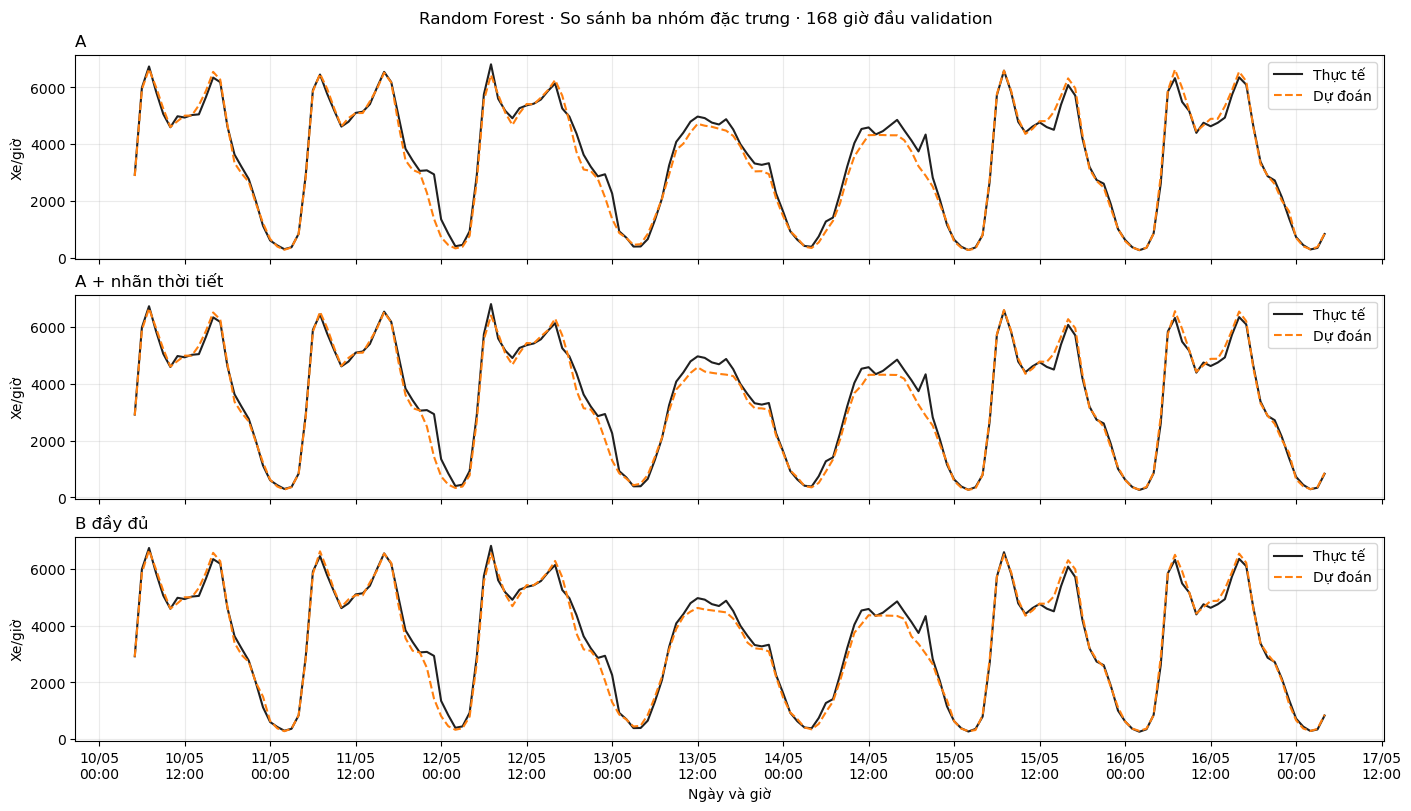

In [14]:
if RUN_VALIDATION:
    import matplotlib.dates as mdates
    import matplotlib.pyplot as plt

    HOURS_TO_PLOT = 7 * 24
    plot_index = pd.date_range(
        start=predictions["date_time"].min(), periods=HOURS_TO_PLOT, freq="h",
    )
    plot_data = predictions.set_index("date_time").reindex(plot_index)
    titles = {"A": "A", "A_labels": "A + nhãn thời tiết", "B": "B đầy đủ"}

    fig, axes = plt.subplots(
        len(CONFIG_FEATURES), 1,
        figsize=(14, 8), sharex=True, sharey=True, layout="constrained",
    )
    for ax, config in zip(axes, CONFIG_FEATURES):
        ax.plot(plot_index, plot_data[TARGET], color="#202020", label="Thực tế")
        ax.plot(
            plot_index, plot_data[config], color="tab:orange",
            linestyle="--", label="Dự đoán",
        )
        ax.set_title(titles[config], loc="left")
        ax.set_ylabel("Xe/giờ")
        ax.grid(alpha=0.25)
        ax.legend(loc="upper right")

    axes[-1].set_xlabel("Ngày và giờ")
    axes[-1].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
    fig.suptitle("Random Forest · So sánh ba nhóm đặc trưng · 168 giờ đầu validation")

    image_dir = OUTPUT_DIR / "img"
    image_dir.mkdir(exist_ok=True)
    fig.savefig(image_dir / "config_b_weather_labels_168h.png", dpi=300, facecolor="white")
    plt.show()

## Nhận xét sau khi chạy

Lần chạy `20261117_203112_824733` so sánh các nhóm đặc trưng với cùng bộ Random Forest và 3 fold theo thời gian. Dòng **A + thời tiết dạng số** lấy từ thí nghiệm trước, lần chạy `20261117_141557_451140`. Hai lần chạy dùng cùng tham số, cùng mốc chia CV và cùng timestamp, lưu lượng thực tế và cờ giờ cao điểm trên **6.086 giờ validation**. MAE và RMSE tính theo xe/giờ.

| Phương án | MAE fold 1 | MAE fold 2 | MAE fold 3 | MAE CV | MAE validation | RMSE validation | MAE cao điểm validation |
|---|---:|---:|---:|---:|---:|---:|---:|
| A | **254,75** | 274,52 | 312,58 | **280,62** | 241,97 | **380,94** | 360,59 |
| A + thời tiết dạng số | 266,37 | 266,10 | 313,73 | 282,07 | 242,27 | 397,21 | 359,70 |
| A + nhãn thời tiết | 258,62 | 275,33 | **311,62** | 281,86 | 241,60 | 386,60 | 362,70 |
| B đầy đủ | 266,83 | **265,30** | 311,72 | 281,28 | **240,10** | 395,49 | **354,09** |

- **Thêm nhãn thời tiết vào A.** MAE tăng **3,87** ở fold 1 và **0,81** ở fold 2, rồi giảm **0,96** ở fold 3. MAE CV trung bình tăng **1,24**. Trên validation, MAE giảm **0,37**, trong khi RMSE tăng **5,66** và MAE giờ cao điểm tăng **2,11**.
- **So hai nhóm thời tiết khi thêm riêng vào A.** Phương án dùng nhãn có MAE validation thấp hơn phương án dùng biến dạng số **0,67** và RMSE thấp hơn **10,61**. Phương án dạng số có MAE giờ cao điểm thấp hơn khoảng **3,00**.
- **Thêm bốn biến dạng số khi đã có nhãn.** B đầy đủ giảm MAE CV **0,57** so với A + nhãn. Trên validation, B giảm MAE **1,50** và MAE giờ cao điểm **8,61**, còn RMSE tăng **8,88**.
- **168 giờ đầu validation.** MAE là **189,78** với A, **182,86** với A + nhãn và **173,47** với B. Cả ba đều dự đoán thấp ở hai giờ có sai số lớn nhất trong đoạn này là **23h ngày 11/05/2017** và **20h ngày 14/05/2017**. Ở mốc thứ hai, lưu lượng thực tế là **4.338 xe/giờ**, A + nhãn dự đoán khoảng **2.879** và B dự đoán khoảng **3.012**.

**Kết luận:** A có MAE CV và RMSE validation thấp nhất. B đầy đủ có MAE validation và MAE giờ cao điểm thấp nhất. Dùng riêng nhãn thời tiết giảm nhẹ MAE validation so với A, đồng thời làm tăng RMSE và MAE giờ cao điểm.